# AMAZON STOCK PRICE ANALYSIS

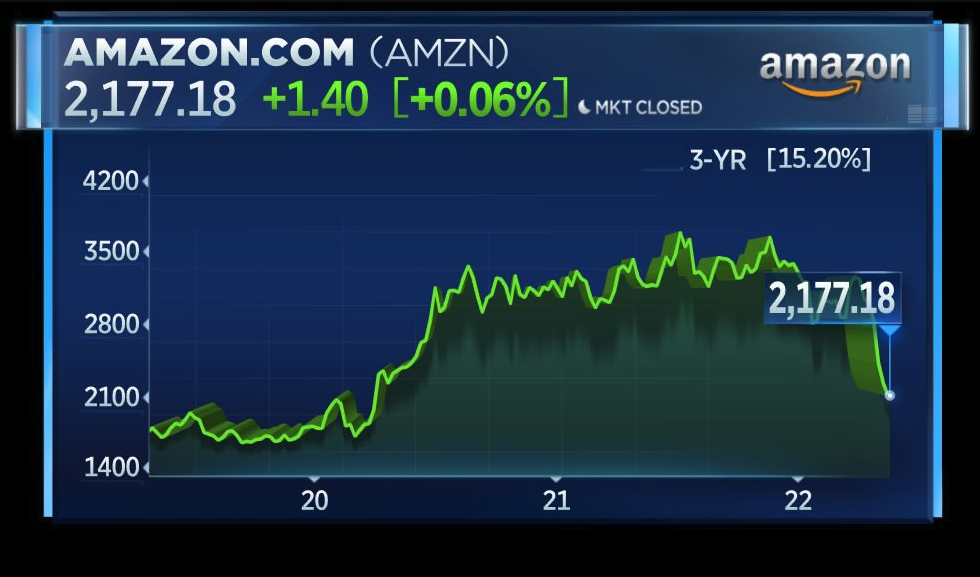

## Introduction

After creating the dataset we will analyze which are the important features and we will attempt to perform a forecasting

## Importing dataset 

In [1]:
import pandas as pd
import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns #viz #plotly is another package
from pandas.plotting import scatter_matrix
%matplotlib inline

<frozen importlib._bootstrap>:228: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


In [2]:
amazon = pd.read_csv('newamazon.csv', index_col='Date')


In [3]:
amazon


,Label,Period,Retail and food Services Sales total,Observation Value,unemplomentrate,Inflation Rate,GDP,Open,High,Low,Close,Adj Close,Volume,MarktCap,MA50,MA200,returns
Date,,,,,,,,,,,,,,,,,
1997-05-15,1997 May,M05,234190.0,159.900,4.9,4.9,8.577554e+12,0.121875,0.125000,0.096354,0.097917,0.097917,1.443120e+09,1.758803e+08,0.0000,0.000000,0.000000
1997-05-16,1997 May,M05,234190.0,159.900,4.9,4.9,8.577554e+12,0.098438,0.098958,0.085417,0.086458,0.086458,2.940000e+08,2.894077e+07,0.0000,0.000000,-0.117028
1997-05-19,1997 May,M05,234190.0,159.900,4.9,4.9,8.577554e+12,0.088021,0.088542,0.081250,0.085417,0.085417,1.221360e+08,1.075053e+07,0.0000,0.000000,-0.012040
1997-05-20,1997 May,M05,234190.0,159.900,4.9,4.9,8.577554e+12,0.086458,0.087500,0.081771,0.081771,0.081771,1.093440e+08,9.453663e+06,0.0000,0.000000,-0.042685
1997-05-21,1997 May,M05,234190.0,159.900,4.9,4.9,8.577554e+12,0.081771,0.082292,0.068750,0.071354,0.071354,3.770640e+08,3.083290e+07,0.0000,0.000000,-0.127392
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-11-03,2022 Oct,M10,648069.0,298.062,3.7,3.7,2.299610e+13,92.470001,93.500000,89.019997,89.300003,89.300003,1.366833e+08,1.263910e+10,118.7850,130.924348,-0.030612
2022-11-04,2022 Oct,M10,648069.0,298.062,3.7,3.7,2.299610e+13,91.489998,92.440002,88.040001,90.980003,90.980003,1.289999e+08,1.180220e+10,117.9096,130.597968,0.018813
2022-11-07,2022 Oct,M10,648069.0,298.062,3.7,3.7,2.299610e+13,91.949997,92.099998,89.040001,90.529999,90.529999,7.749570e+07,7.125729e+09,117.0176,130.307968,-0.004946


In [4]:
amazon.describe()

,Retail and food Services Sales total,Observation Value,unemplomentrate,Inflation Rate,GDP,Open,High,Low,Close,Adj Close,Volume,MarktCap,MA50,MA200,returns
count,6525.000000,6525.000000,6525.000000,6525.000000,6.525000e+03,6525.000000,6525.000000,6525.000000,6525.000000,6525.000000,6.525000e+03,6.525000e+03,6525.000000,6525.000000,6525.000000
mean,389398.244567,216.514378,5.725686,5.725686,1.543011e+13,30.585128,30.945641,30.183325,30.567329,30.567329,1.435324e+08,2.676938e+09,30.168235,28.685968,0.001644
std,105641.097930,34.267796,1.897538,1.897538,4.205084e+12,47.762137,48.310573,47.137289,47.714498,47.714498,1.404824e+08,4.321018e+09,47.436344,46.065699,0.036244
min,203863.000000,159.900000,3.500000,3.500000,8.577554e+12,0.070313,0.072396,0.065625,0.069792,0.069792,9.744000e+06,8.935645e+05,0.000000,0.000000,-0.247661
25%,309923.000000,184.900000,4.400000,4.400000,1.145644e+13,1.977500,2.014000,1.943500,1.984500,1.984500,6.950200e+07,3.010144e+08,1.968610,1.984170,-0.013308
50%,375025.000000,217.463000,5.000000,5.000000,1.504896e+13,6.180500,6.295000,6.077500,6.189500,6.189500,1.066300e+08,7.830050e+08,6.107290,5.048532,0.000346
75%,459763.000000,240.101000,6.300000,6.300000,1.869511e+13,36.117500,36.400002,35.827000,36.187000,36.187000,1.619100e+08,2.637926e+09,34.423160,30.814908,0.014669
max,711673.000000,298.062000,14.700000,14.700000,2.299610e+13,187.199997,188.654007,184.839493,186.570496,186.570496,2.086584e+09,3.943940e+10,173.707089,169.803395,0.344714


In [5]:
amazon['Period'].value_counts()

M10    587
M08    583
M06    563
M07    557
M03    556
M05    546
M09    539
M12    536
M01    530
M04    524
M11    518
M02    486
Name: Period, dtype: int64

In [6]:
amazon.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6525 entries, 1997-05-15 to 2022-11-09
Data columns (total 17 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Label                                 6525 non-null   object 
 1   Period                                6525 non-null   object 
 2   Retail and food Services Sales total  6525 non-null   float64
 3   Observation Value                     6525 non-null   float64
 4   unemplomentrate                       6525 non-null   float64
 5   Inflation Rate                        6525 non-null   float64
 6   GDP                                   6525 non-null   float64
 7   Open                                  6525 non-null   float64
 8   High                                  6525 non-null   float64
 9   Low                                   6525 non-null   float64
 10  Close                                 6525 non-null   float64
 11  Adj Clo

In [7]:
# To work better with the data the Date index will be changed to datetime
amazon.index = pd.to_datetime(amazon.index)
amazon.head()

,Label,Period,Retail and food Services Sales total,Observation Value,unemplomentrate,Inflation Rate,GDP,Open,High,Low,Close,Adj Close,Volume,MarktCap,MA50,MA200,returns
Date,,,,,,,,,,,,,,,,,
1997-05-15,1997 May,M05,234190.0,159.9,4.9,4.9,8.577554e+12,0.121875,0.125000,0.096354,0.097917,0.097917,1.443120e+09,1.758803e+08,0.0,0.0,0.000000
1997-05-16,1997 May,M05,234190.0,159.9,4.9,4.9,8.577554e+12,0.098438,0.098958,0.085417,0.086458,0.086458,2.940000e+08,2.894077e+07,0.0,0.0,-0.117028
1997-05-19,1997 May,M05,234190.0,159.9,4.9,4.9,8.577554e+12,0.088021,0.088542,0.081250,0.085417,0.085417,1.221360e+08,1.075053e+07,0.0,0.0,-0.012040
1997-05-20,1997 May,M05,234190.0,159.9,4.9,4.9,8.577554e+12,0.086458,0.087500,0.081771,0.081771,0.081771,1.093440e+08,9.453663e+06,0.0,0.0,-0.042685
1997-05-21,1997 May,M05,234190.0,159.9,4.9,4.9,8.577554e+12,0.081771,0.082292,0.068750,0.071354,0.071354,3.770640e+08,3.083290e+07,0.0,0.0,-0.127392


## YOY Closing price

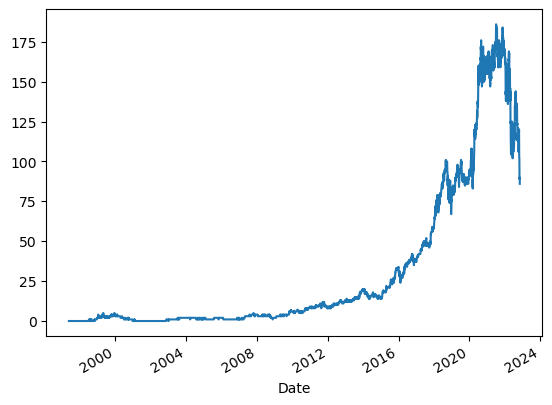

In [185]:
amazon['Close'].plot();

## Monthly comparison

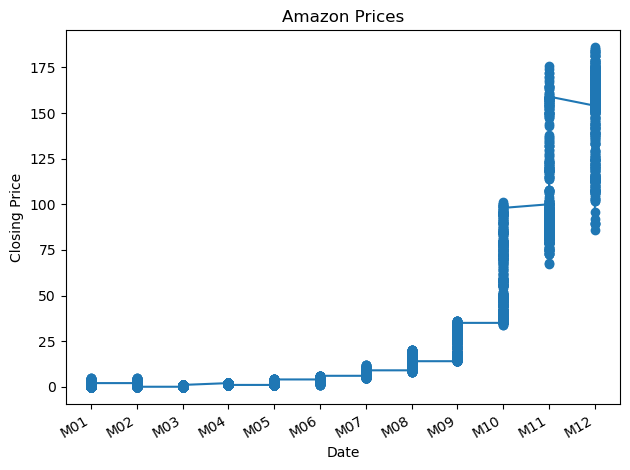

In [187]:
price_date = amazon['Period'].sort_values()
price_close = amazon['Close']

plt.plot_date(price_date, price_close, linestyle='solid')

plt.gcf().autofmt_xdate()


plt.title('Amazon Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')

plt.tight_layout()


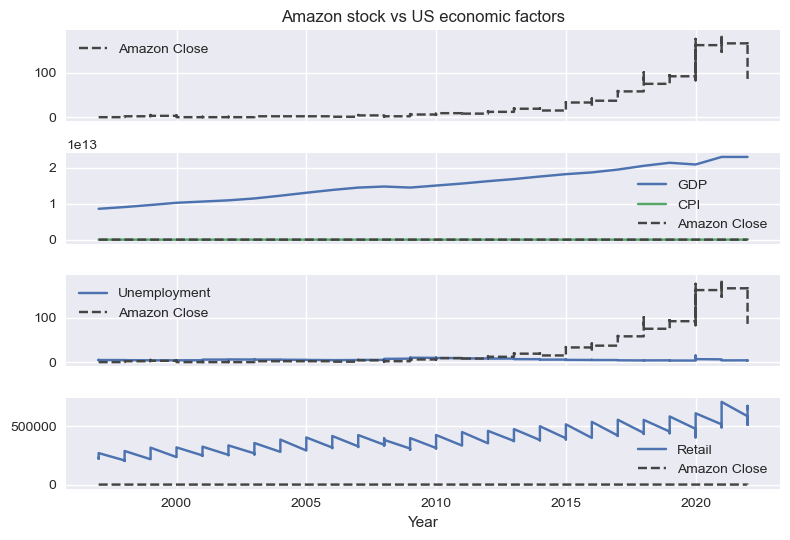

In [241]:
year = pd.DatetimeIndex(amazon.index).year
close = amazon['Close']
GDP = amazon['GDP']
unemployment = amazon['unemplomentrate']
retail = amazon['Retail and food Services Sales total']
cpi = amazon['Observation Value']

plt.style.use('seaborn')



fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1, sharex = True)


ax1.plot(year, close, color='#444444',
         linestyle='--', label='Amazon Close')

ax2.plot(year, GDP, label='GDP')
ax2.plot(year, cpi, label='CPI')
ax2.plot(year, close, color='#444444',
         linestyle='--', label='Amazon Close')

ax3.plot(year, unemployment, label='Unemployment')
ax3.plot(year, close, color='#444444',
         linestyle='--', label='Amazon Close')

ax4.plot(year, retail, label='Retail')
ax4.plot(year, close, color='#444444',
         linestyle='--', label='Amazon Close')

ax1.legend()
ax1.set_title('Amazon stock vs US economic factors')


ax2.legend()

ax3.legend()

ax4.legend()
ax4.set_xlabel('Year')


plt.tight_layout()

### Autocorrelation 

In [10]:
from statsmodels.graphics.tsaplots import plot_acf #autocorrelation plot

In [11]:
period_df = amazon[['Period','Close']]

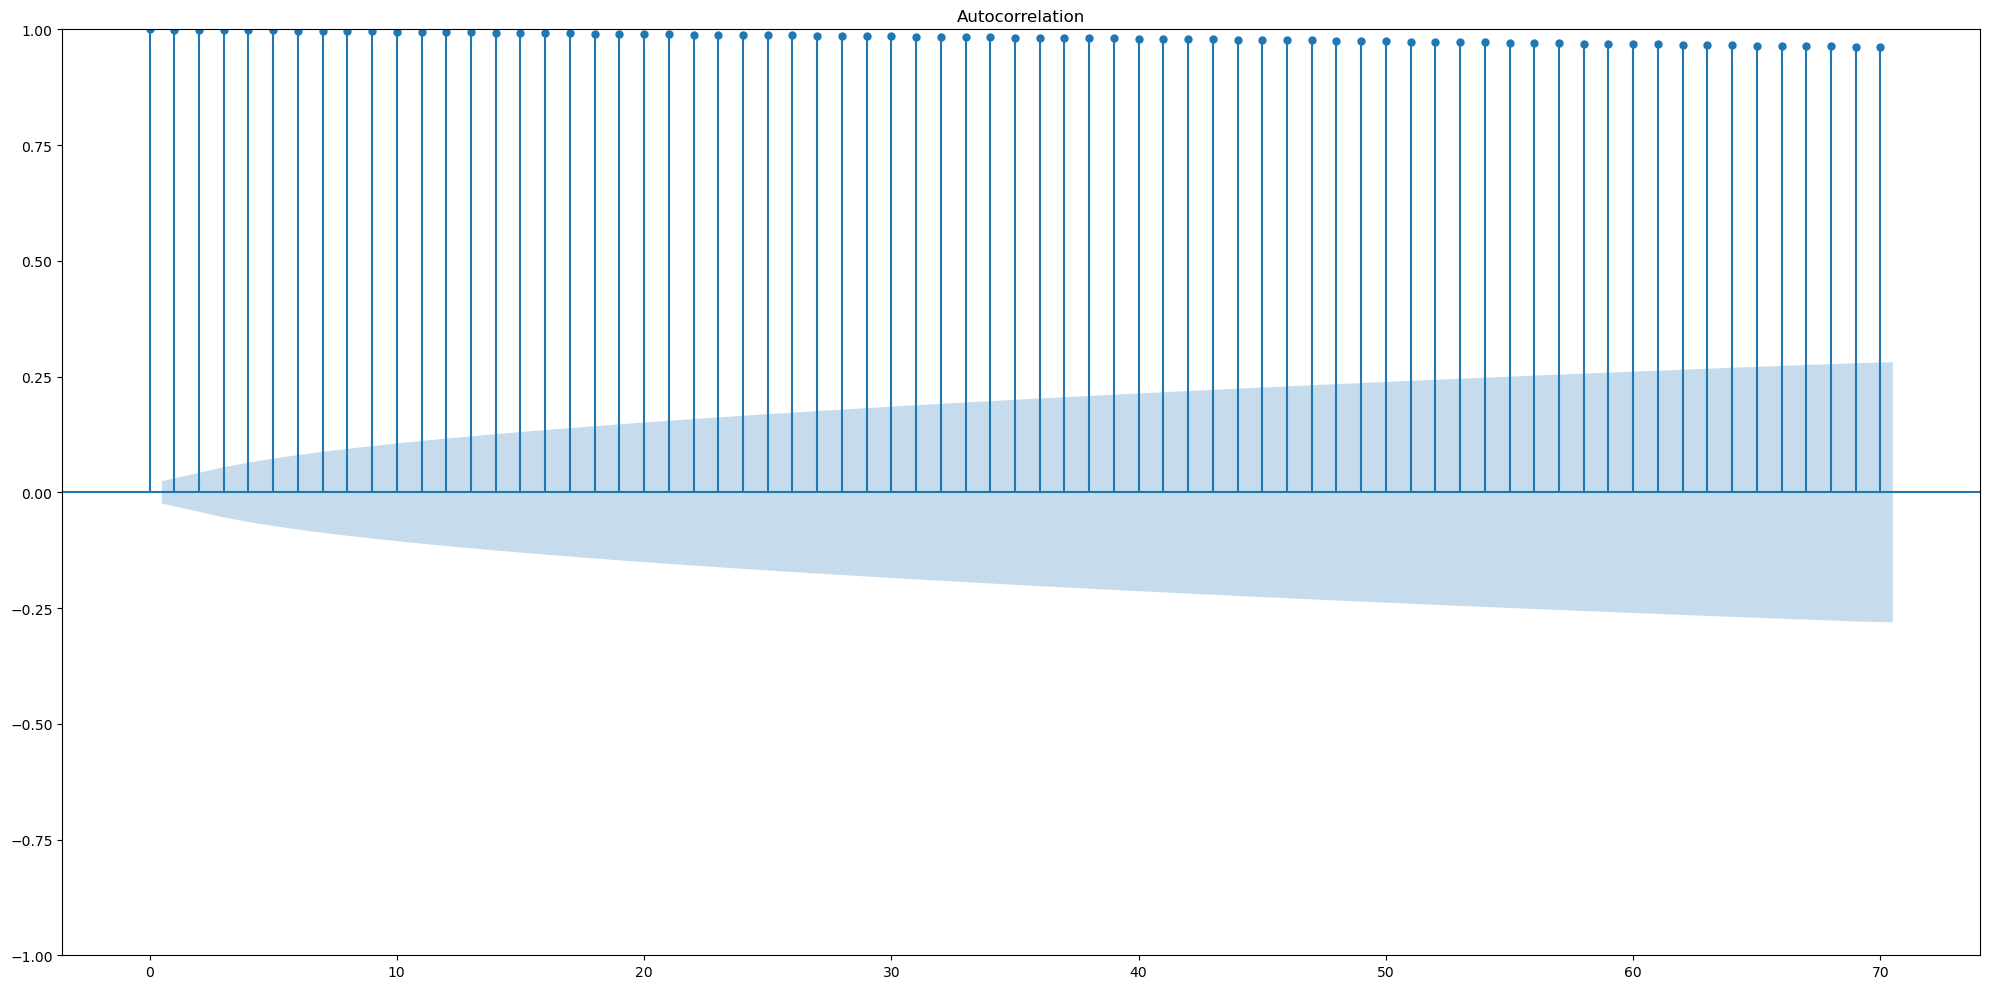

In [12]:
fig = plot_acf(period_df['Close'], lags=70)
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

In [189]:
returnsclose = amazon[['returns','Close']]

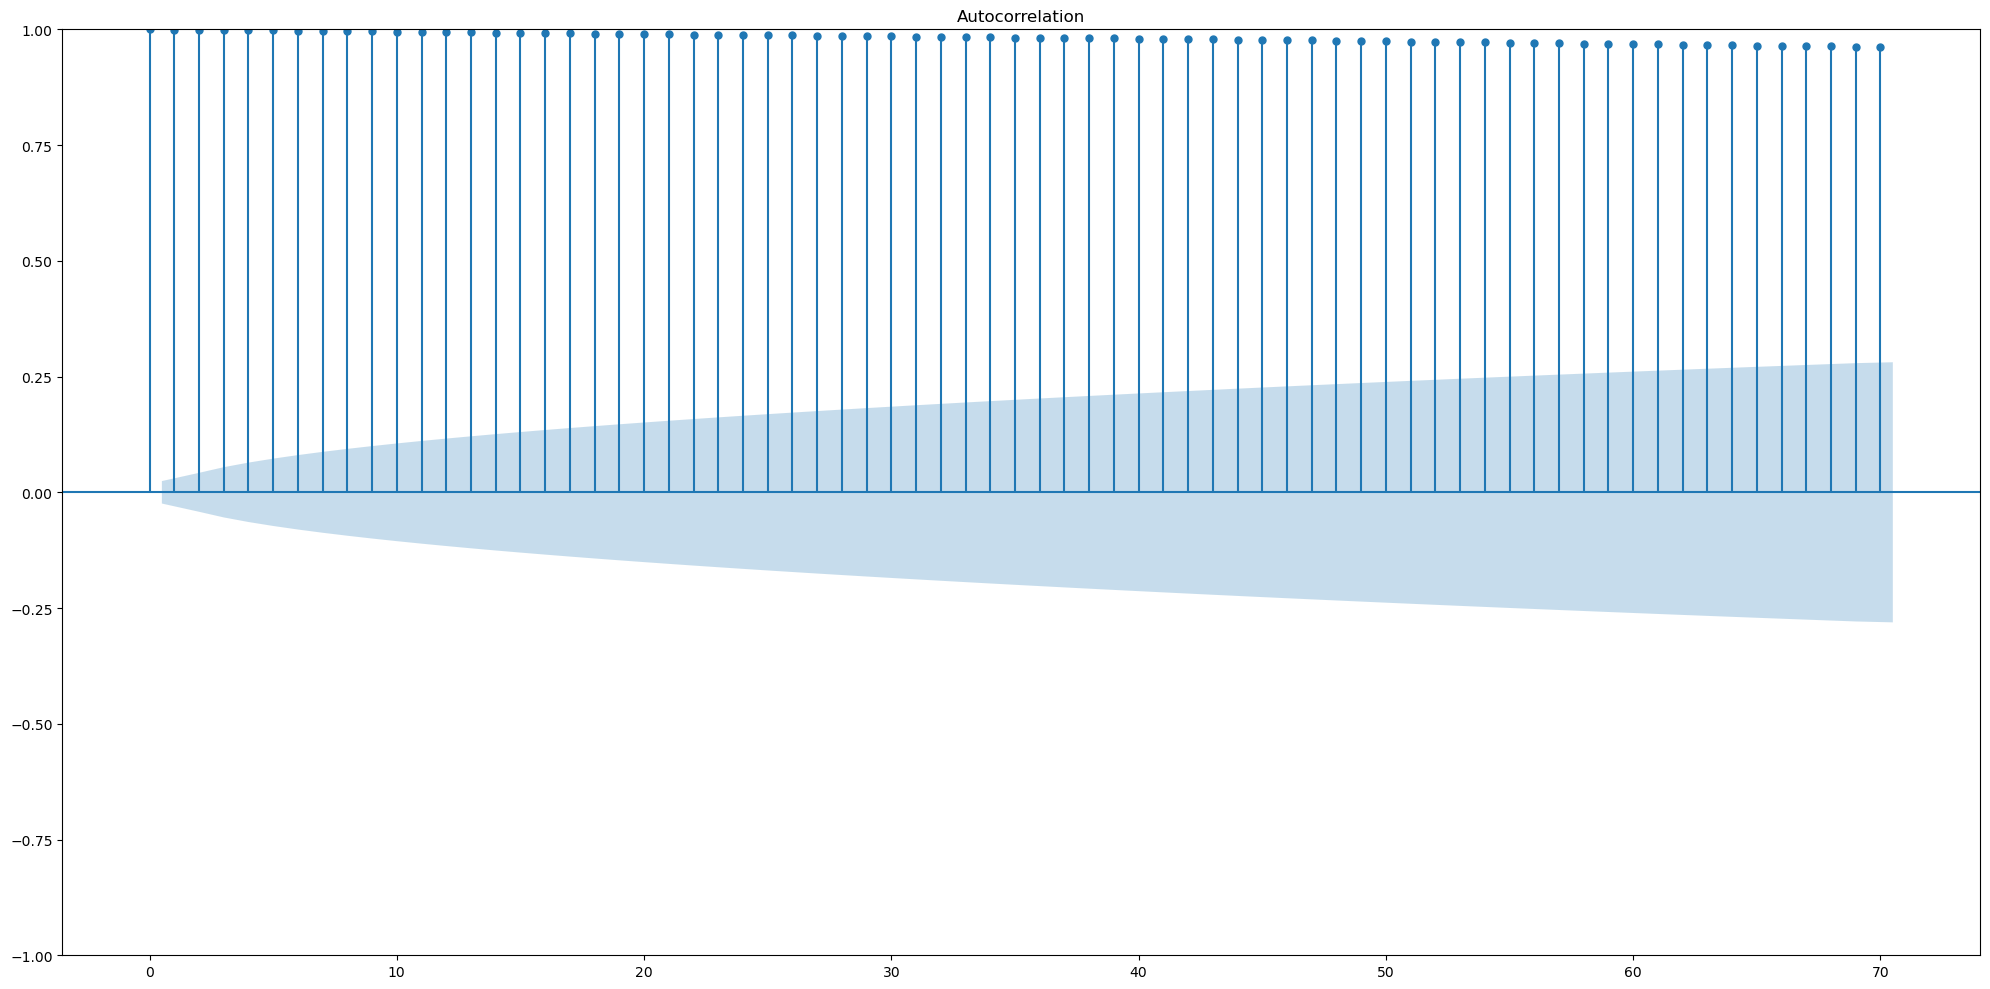

In [190]:
fig = plot_acf(returnsclose['Close'], lags=70)
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

### Decomposition of time

In [191]:
import statsmodels.api as sm 
from statsmodels.graphics.tsaplots import plot_acf #autocorrelation plot
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing # double and triple exponential smoothing
from pandas.plotting import autocorrelation_plot #autocorrelation plot
from statsmodels.graphics.gofplots import qqplot #residual diagnostics
from sklearn.metrics import mean_squared_error #accuracy metrics
from math import sqrt
from sklearn.metrics import mean_absolute_error #accuracy metrics

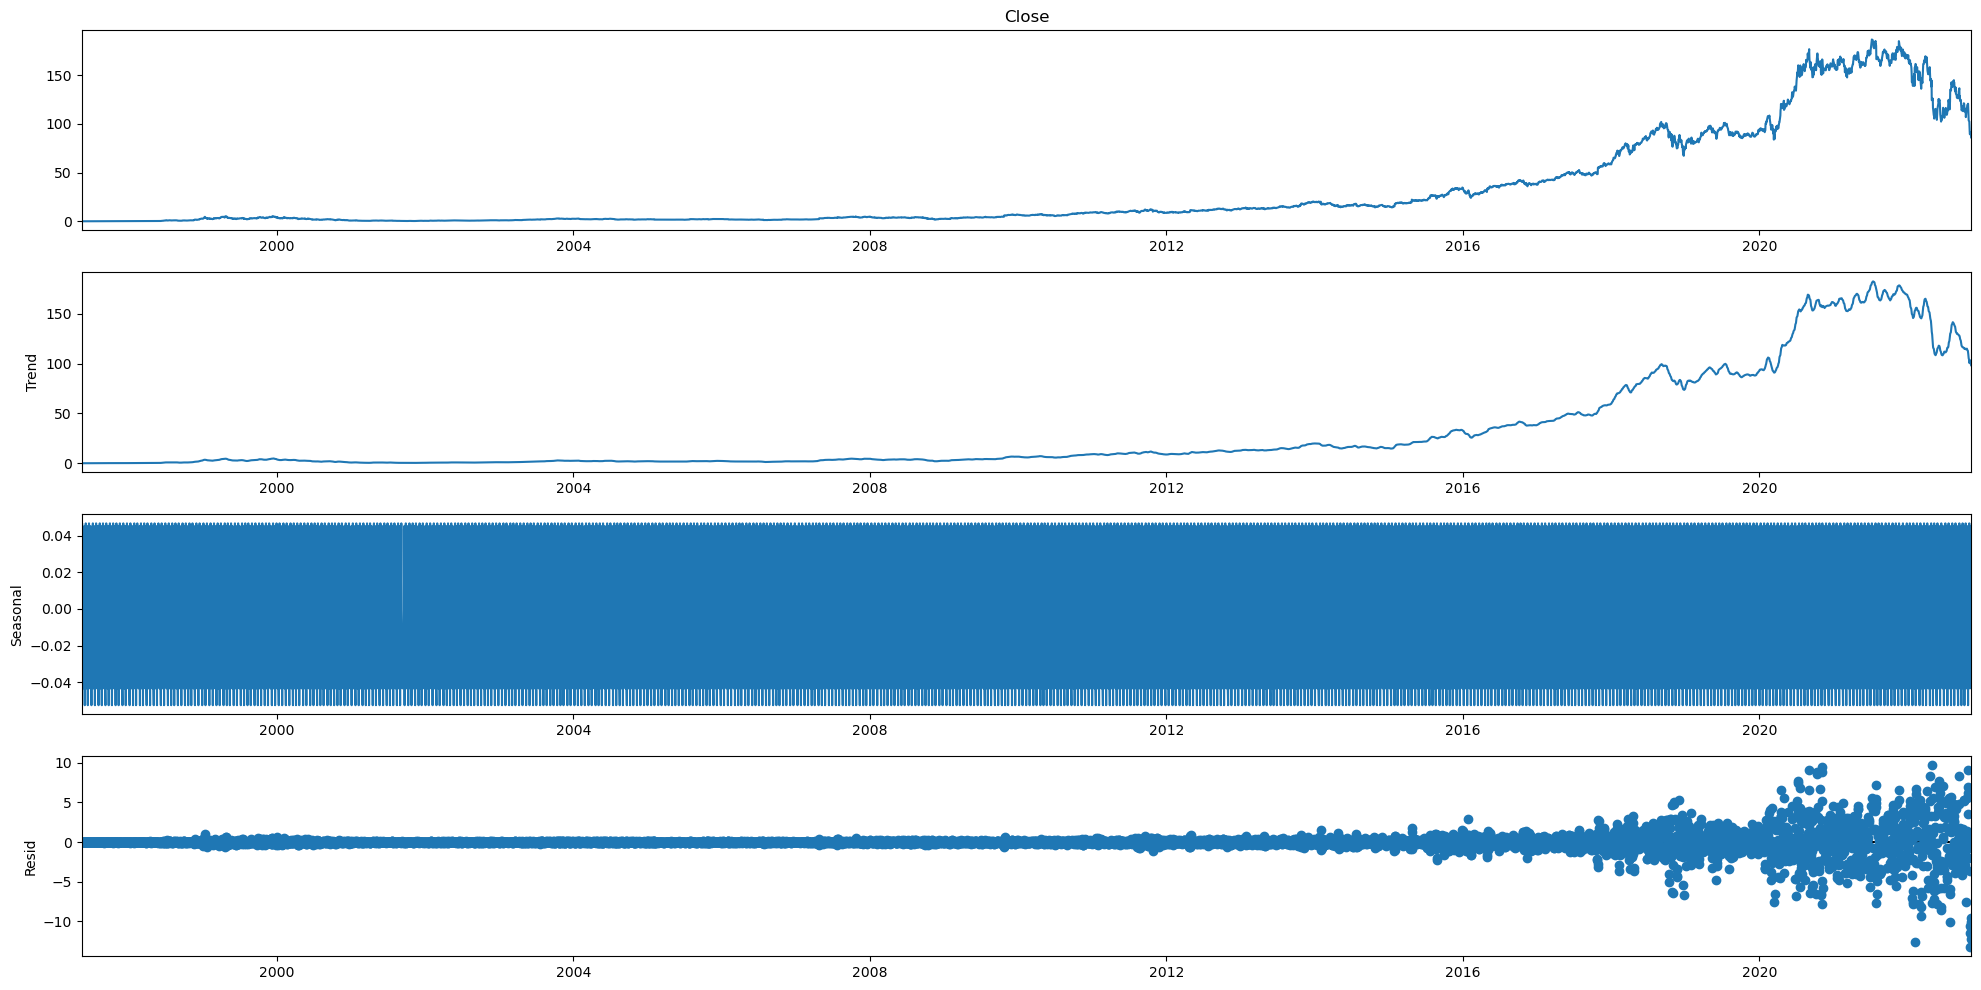

In [192]:
res = sm.tsa.seasonal_decompose(period_df['Close'], period=12, extrapolate_trend='freq')
fig = res.plot()
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

### Correlation with Closing price

In [193]:
amazon.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6525 entries, 1997-05-15 to 2022-11-09
Data columns (total 17 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Label                                 6525 non-null   object 
 1   Period                                6525 non-null   object 
 2   Retail and food Services Sales total  6525 non-null   float64
 3   Observation Value                     6525 non-null   float64
 4   unemplomentrate                       6525 non-null   float64
 5   Inflation Rate                        6525 non-null   float64
 6   GDP                                   6525 non-null   float64
 7   Open                                  6525 non-null   float64
 8   High                                  6525 non-null   float64
 9   Low                                   6525 non-null   float64
 10  Close                                 6525 non-null   int64  
 11 

In [194]:
amazon['Close'] = amazon['Close'].astype('int')

### Feature Selection and correlation

In [195]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn import preprocessing
from sklearn import utils

In [196]:
X = amazon.drop(['Label', 'Period'], axis=1)
y = amazon['Close']

In [197]:
# Split into train and test

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [198]:
# to get the column names of the top 10 correlated columns with 'SalePrice'
top10 = abs(X_train.corr()['Close']).sort_values(ascending=False).head(11).index.drop('Close')

In [199]:
# normalize data

norm = MinMaxScaler().fit(X_train)

X_train_norm = norm.transform(X_train)
X_test_norm = norm.transform(X_test)

In [200]:
#Standardize data
stand = StandardScaler().fit(X_train)

X_train_stand = stand.transform(X_train)
X_test_stand = stand.transform(X_test)

In [201]:
# Compare sets

score = []

X_trains = [X_train, X_train_norm, X_train_stand]
X_tests = [X_test, X_test_norm, X_test_stand]

for X_train_set, X_test_set in zip(X_trains, X_tests):
    svc = SVC()
    svc.fit(X_train_set, y_train)
    y_pred = svc.predict(X_test_set)
    score.append(accuracy_score(y_test, y_pred))
    

In [202]:
pd.DataFrame({'score': score}, index=['Original', 'Normalized', 'Standardized'])

,score
Original,0.248162
Normalized,0.368873
Standardized,0.393382


### Finding the most important feature

In [203]:
svc = SVC()
svc.fit(X_train_stand, y_train) # X_train_stand is the best one

perm_importance = permutation_importance(svc, X_test_stand, y_test)
perm_importance.importances_mean

array([0.05882353, 0.12438725, 0.06654412, 0.06654412, 0.12230392,
       0.04203431, 0.04191176, 0.04215686, 0.04460784, 0.04191176,
       0.03161765, 0.05784314, 0.03737745, 0.02977941, 0.00134804])

### Visualizing results

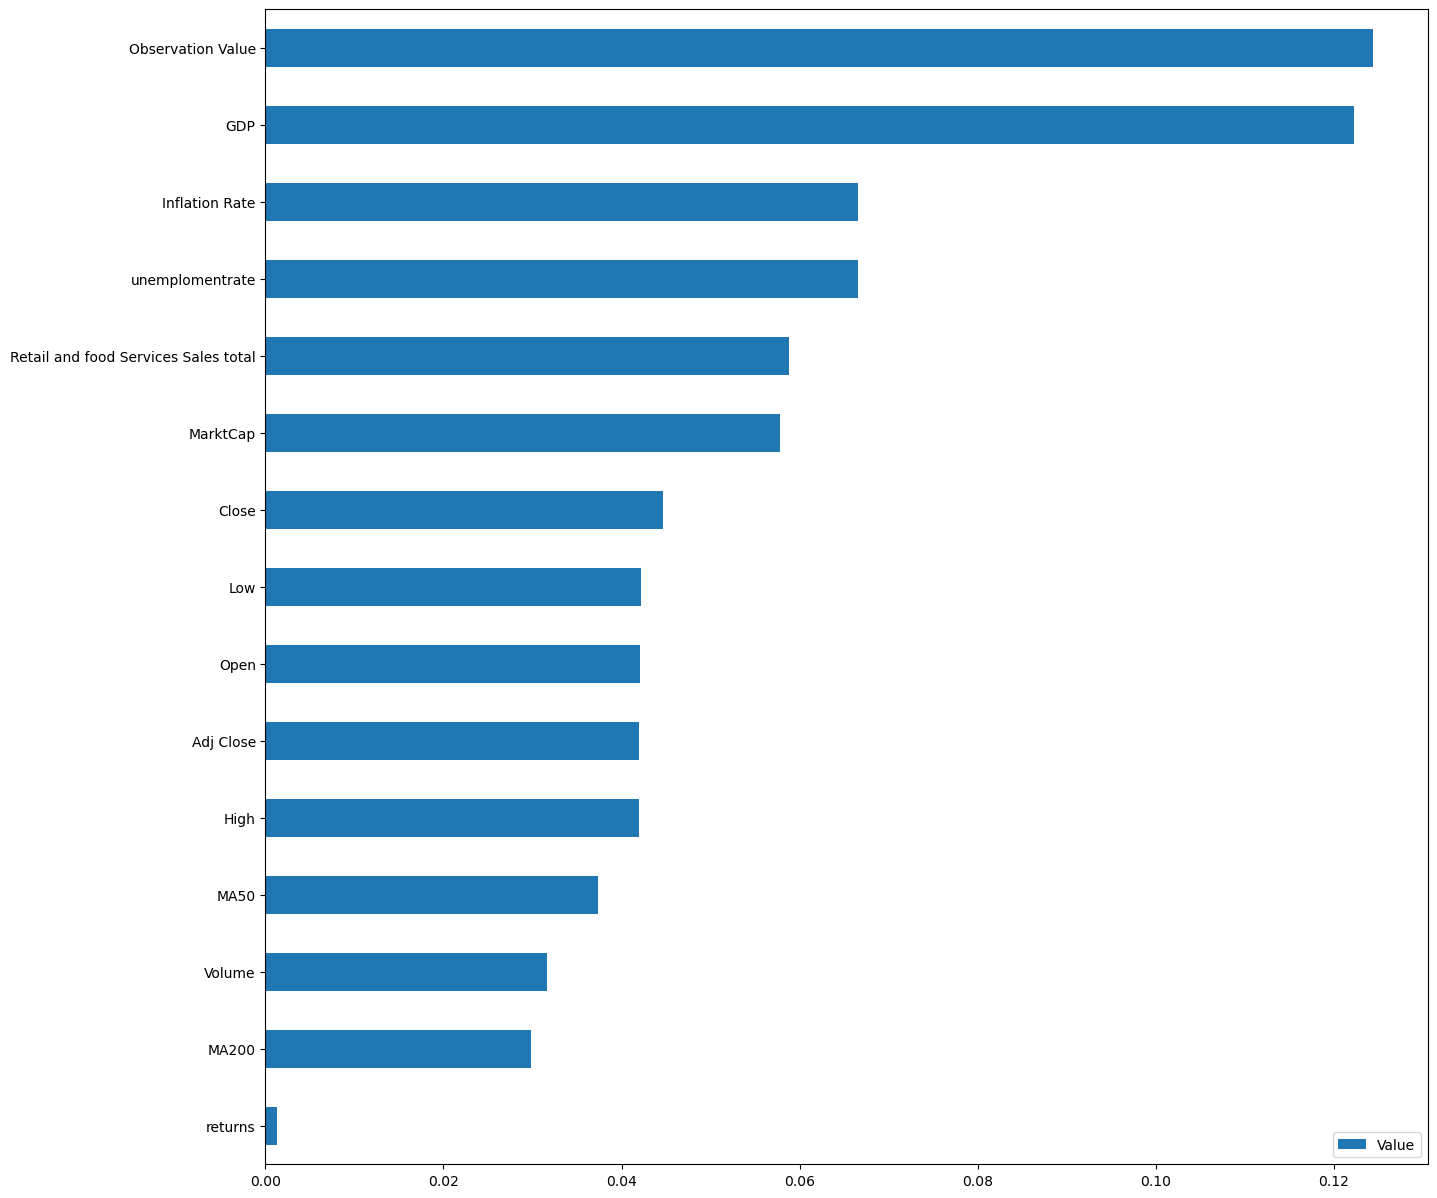

In [204]:
sorted_idx = perm_importance.importances_mean.argsort()
df = pd.DataFrame(perm_importance.importances_mean[sorted_idx], X_test.columns[sorted_idx], columns=['Value'])

df.plot.barh(figsize=[15, 15]);

With the above graph we can see that GDP is one of the highest ones. however this may be due to overfitting the data when filling with NaN values, further investigation is needed. The highest one is CPI (Consumer Price Index), which is logical due to the weighted average market based on consumer goods and services. Given that Amazon sells household products, this would highly impact the stock price.  

## Second training set sample

In [207]:
period_df_resampled = period_df.groupby(pd.Grouper(freq='MS')).median()
period_df_resampled

,Close
Date,
1997-05-01,0.076563
1997-06-01,0.075521
1997-07-01,0.113802
1997-08-01,0.110417
1997-09-01,0.166406
...,...
2022-07-01,115.174999
2022-08-01,138.229996
2022-09-01,124.660004


In [208]:
close1 = period_df_resampled[['Close']]
close1

,Close
Date,
1997-05-01,0.076563
1997-06-01,0.075521
1997-07-01,0.113802
1997-08-01,0.110417
1997-09-01,0.166406
...,...
2022-07-01,115.174999
2022-08-01,138.229996
2022-09-01,124.660004


In [209]:
close1['trend'] = res.trend
close1['seasonal'] = res.seasonal
close1['error'] = res.resid
close1

,Close,trend,seasonal,error
Date,,,,
1997-05-01,0.076563,NaN,NaN,NaN
1997-06-01,0.075521,0.076107,-0.020495,0.019388
1997-07-01,0.113802,0.088477,-0.052606,0.039911
1997-08-01,0.110417,0.115940,0.045255,-0.040362
1997-09-01,0.166406,0.122309,-0.043413,0.038031
...,...,...,...,...
2022-07-01,115.174999,112.004167,0.037900,-2.482070
2022-08-01,138.229996,131.343751,-0.029489,4.075737
2022-09-01,124.660004,130.204583,0.045255,-2.429838


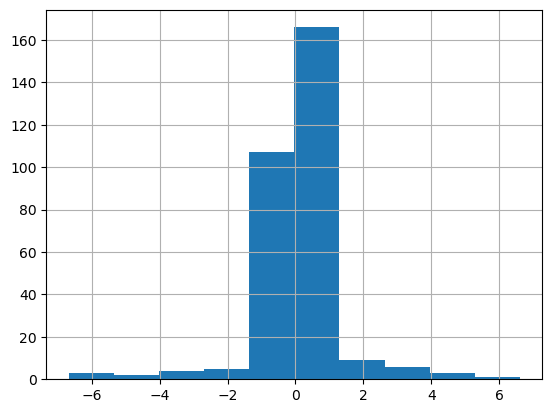

In [210]:
close1['error'].hist();

In [211]:
close = period_df_resampled[['Close']]
close

,Close
Date,
1997-05-01,0.076563
1997-06-01,0.075521
1997-07-01,0.113802
1997-08-01,0.110417
1997-09-01,0.166406
...,...
2022-07-01,115.174999
2022-08-01,138.229996
2022-09-01,124.660004


In [212]:
train_data, test_data = train_test_split(close, test_size=0.11, random_state=25, shuffle = False)
#shuffle = False is very important to ensure the order of the data

print(f"No. of training examples: {train_data.shape[0]}")
print(f"No. of testing examples: {test_data.shape[0]}")

No. of training examples: 273
No. of testing examples: 34


In [213]:
train_data

,Close
Date,
1997-05-01,0.076563
1997-06-01,0.075521
1997-07-01,0.113802
1997-08-01,0.110417
1997-09-01,0.166406
...,...
2019-09-01,90.391998
2019-10-01,88.066498
2019-11-01,88.796001


In [214]:
test_data

,Close
Date,
2020-02-01,103.237747
2020-03-01,94.591003
2020-04-01,115.704002
2020-05-01,120.252499
2020-06-01,131.406250
2020-07-01,152.677246
2020-08-01,160.750748
2020-09-01,157.244003
2020-10-01,160.356255


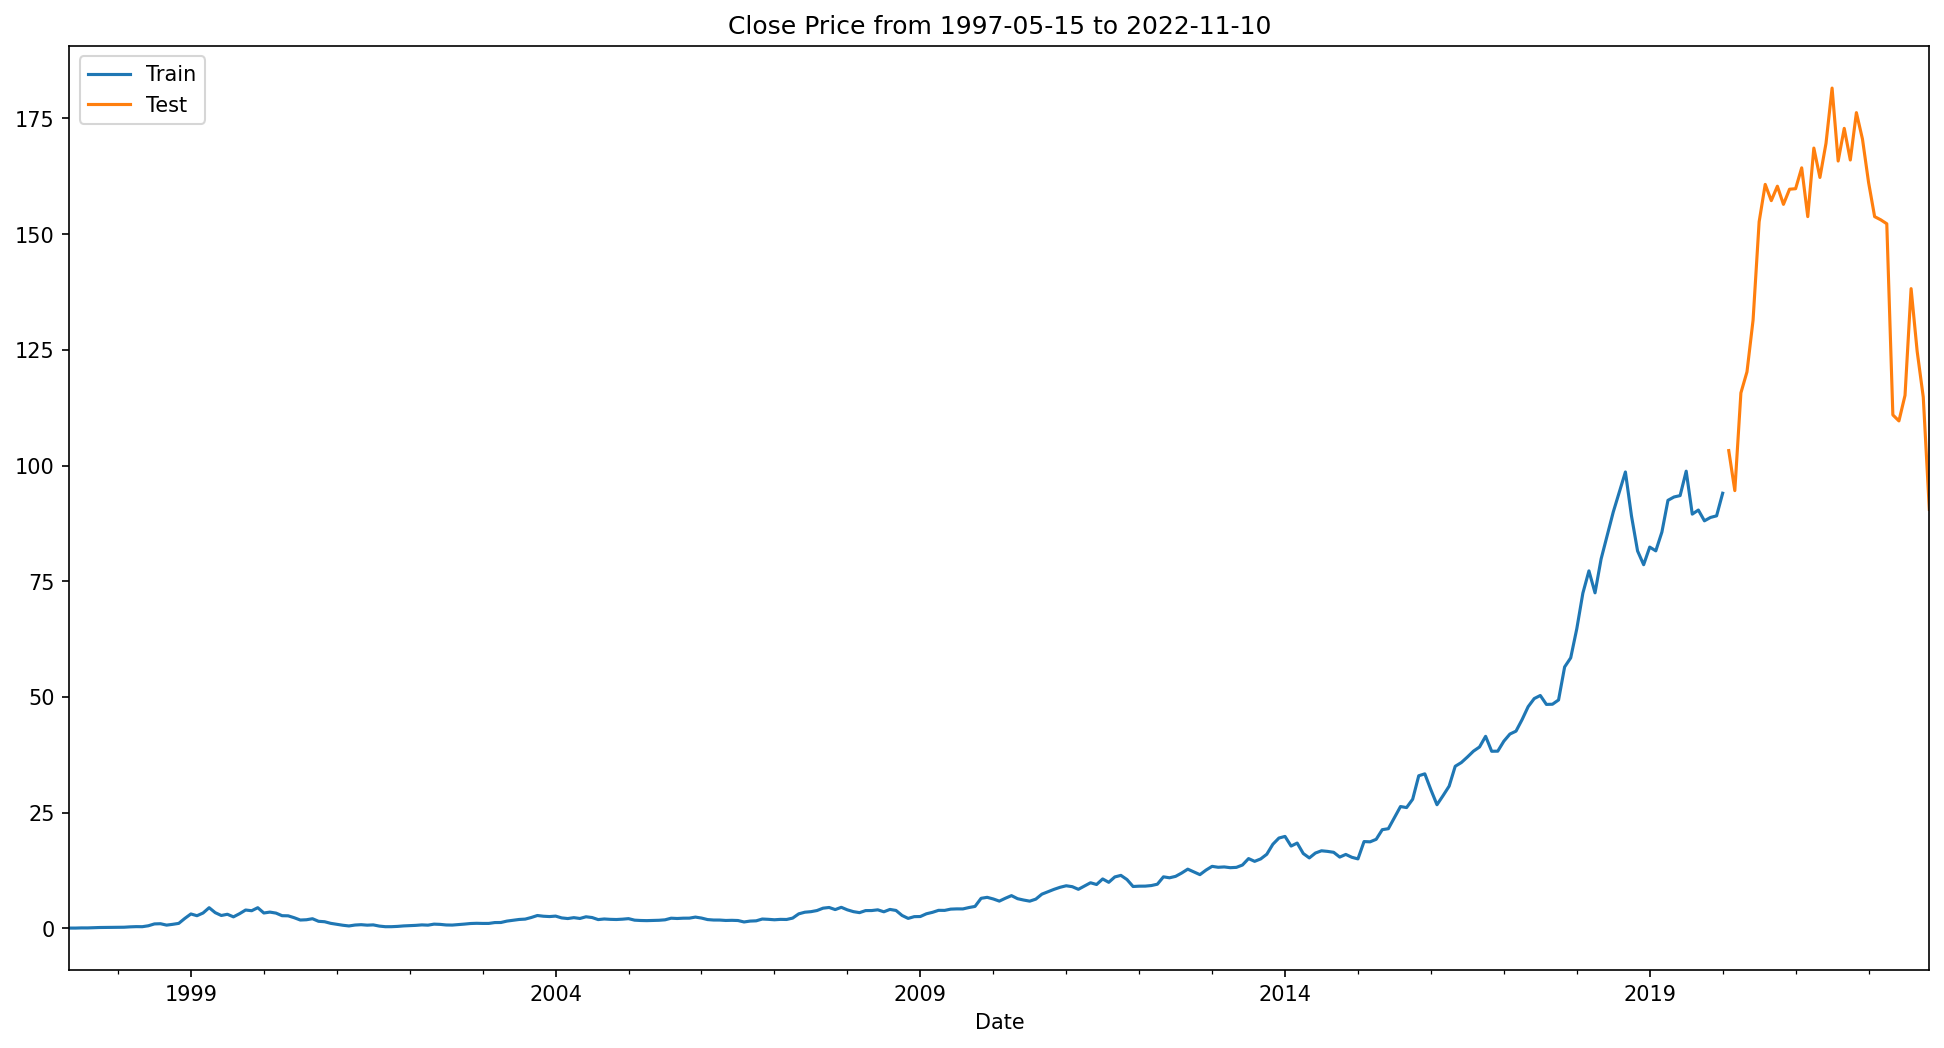

In [215]:
#Plot train and test data

start = "1997-05-15"
end = '2022-11-10'

# to set the plot size
plt.figure(figsize=(16, 8), dpi=150)
  
# using plot method to plot close prices.
# in plot method we set the label and color of the curve.
train_data['Close'].plot(label='Train')
test_data['Close'].plot(label='Test')

  
# adding title to the plot
plt.title('Close Price from {} to {}'.format(start, end))
  
# adding Label to the x-axis
plt.xlabel('Date')
  
# adding legend to the curve
plt.legend();


### Simple Exponential models

In [216]:
#First Instance
ins1 = SimpleExpSmoothing(train_data).fit(smoothing_level=0.2,optimized=False)
ins_cast1 = ins1.forecast(34).rename('alpha=0.2')

#Second Instance
ins2 = SimpleExpSmoothing(train_data).fit(smoothing_level=0.8,optimized=False)
ins_cast2 = ins2.forecast(34).rename('alpha=0.5')

#Third Instance
ins3 = SimpleExpSmoothing(train_data).fit()
ins_cast3 = ins3.forecast(34).rename('alpha=%s'%ins3.model.params['smoothing_level'])


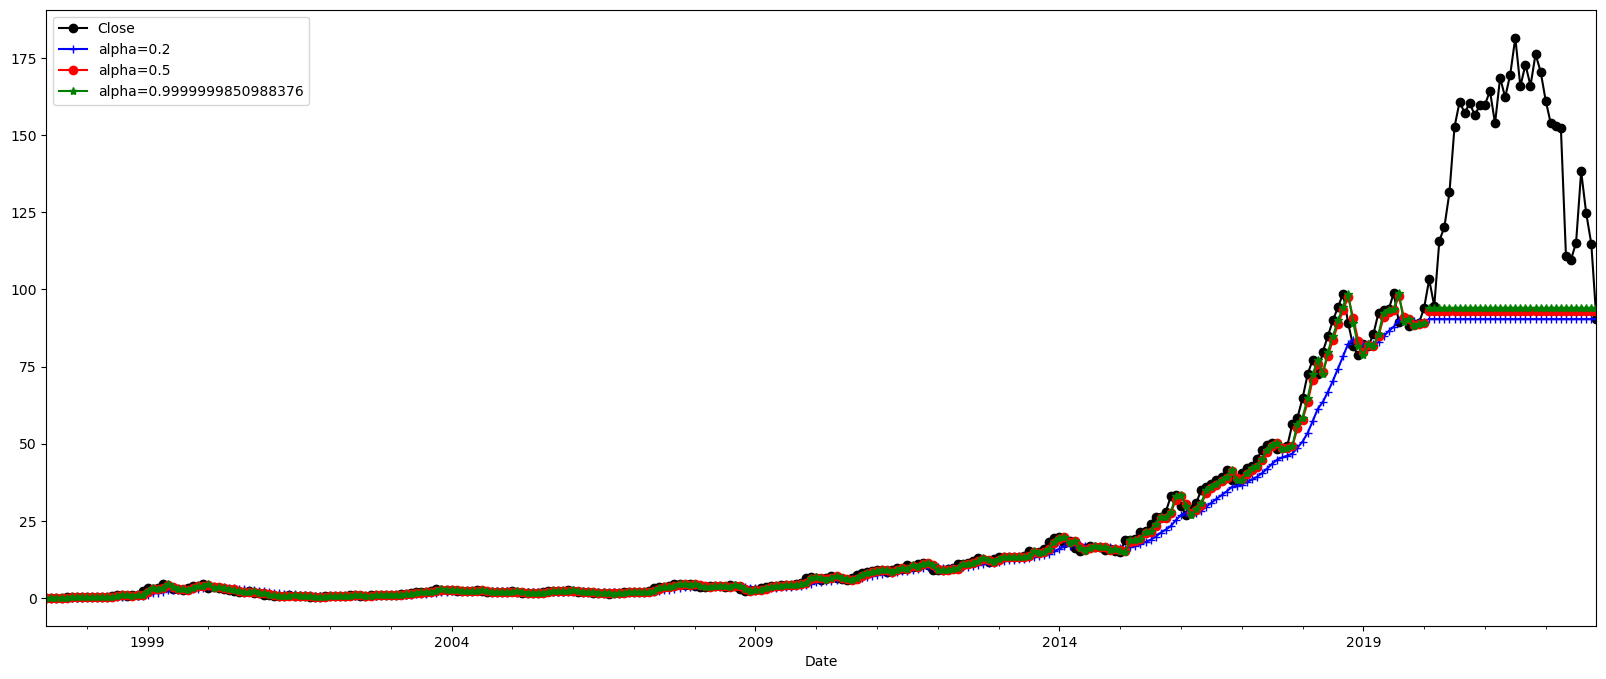

In [218]:
#After creating model we will visualize the plot
ax = close.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for alpha =0.2
ins_cast1.plot(marker='+', ax=ax, color='blue', legend=True)
ins1.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for alpha = 0.5
ins_cast2.plot(marker='o', ax=ax, color='red', legend=True)
ins2.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')

plt.show()

#### Double Exponential Smoothing 

In [219]:
double_ets_add = ExponentialSmoothing(train_data, trend = 'add').fit()
double_ets_mul = ExponentialSmoothing(train_data, trend = 'mul').fit()

double_ets_add_pred = double_ets_add.forecast(34)
double_ets_mul_pred = double_ets_mul.forecast(34)

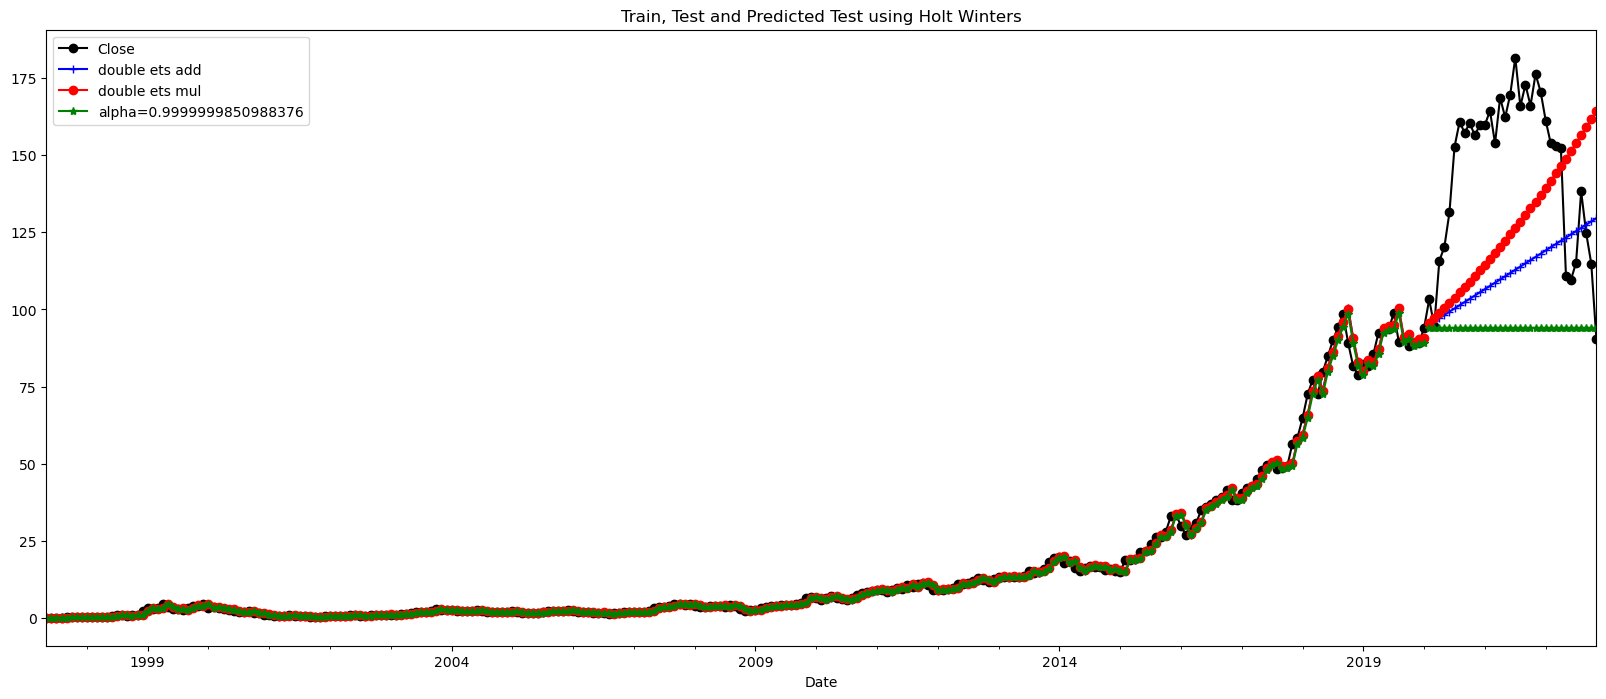

In [220]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = close.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
double_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'double ets add')
double_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
double_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'double ets mul')
double_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Holt Winters')
plt.show()

#### Triple Exponential Smoothing 

In [221]:
# triple ETS - Holt Winter's Seasonal Method
triple_ets_add = ExponentialSmoothing(train_data, trend = 'add', seasonal = 'add', seasonal_periods=34).fit()
triple_ets_mul = ExponentialSmoothing(train_data, trend = 'mul', seasonal = 'mul', seasonal_periods=34).fit()

triple_ets_add_pred = triple_ets_add.forecast(34)
triple_ets_mul_pred = triple_ets_mul.forecast(34)


/Users/paolagarcia/opt/anaconda3/lib/python3.9/site-packages/statsmodels/tsa/holtwinters/model.py:83: RuntimeWarning: overflow encountered in matmul
  return err.T @ err
/Users/paolagarcia/opt/anaconda3/lib/python3.9/site-packages/statsmodels/tsa/holtwinters/model.py:915: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


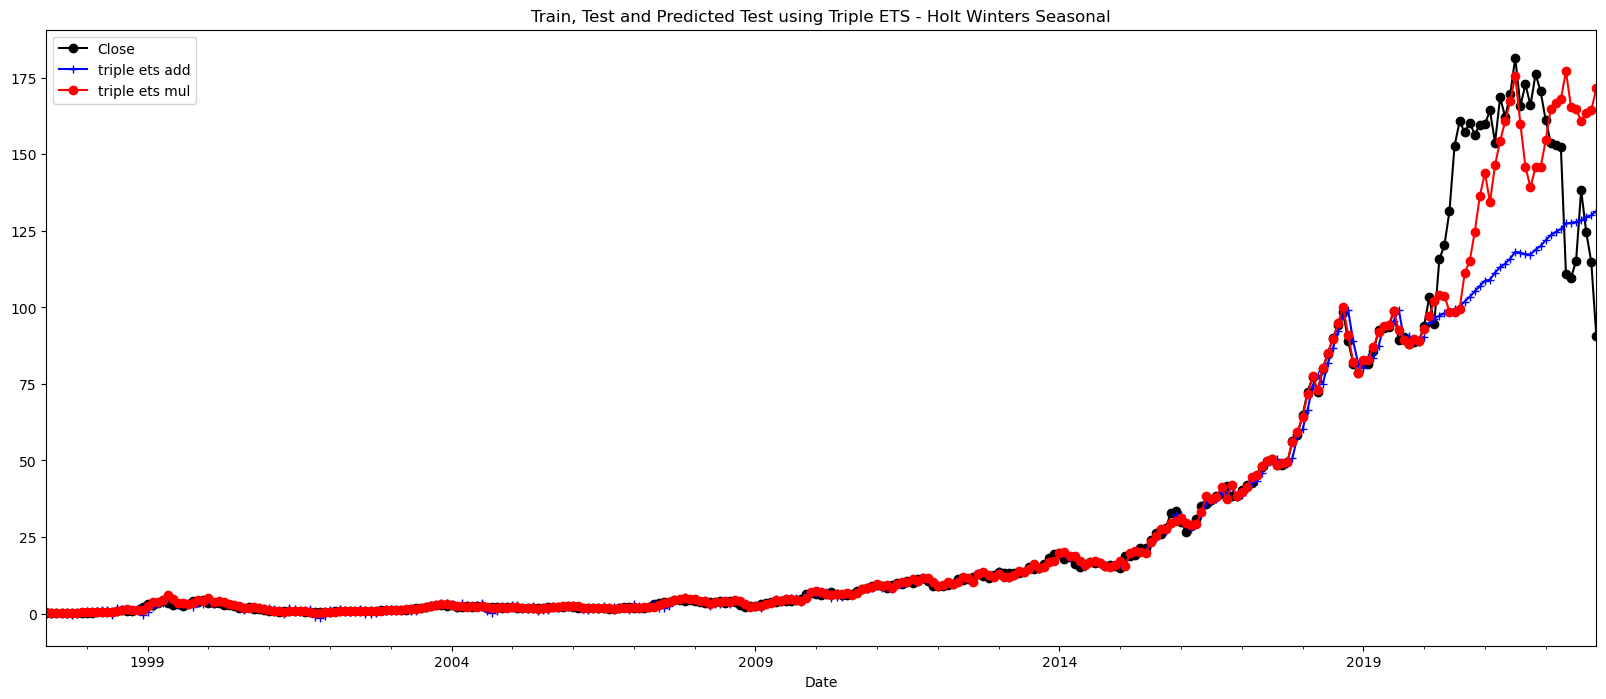

In [222]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = close.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
triple_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'triple ets add')
triple_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
triple_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'triple ets mul')
triple_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
#ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
#ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Triple ETS - Holt Winters Seasonal')
plt.show()

## Visualize Forecast Errors

In [223]:
#calculate residuals
residuals = [test_data.values.flatten()[i]-triple_ets_add_pred.values.flatten()[0] for i in range(len(test_data))]
residuals = pd.DataFrame(residuals)

In [224]:
residuals

,0
0,8.212945
1,-0.433799
2,20.679200
3,25.227696
4,36.381447
5,57.652444
6,65.725945
7,62.219201
8,65.331452
9,61.415703


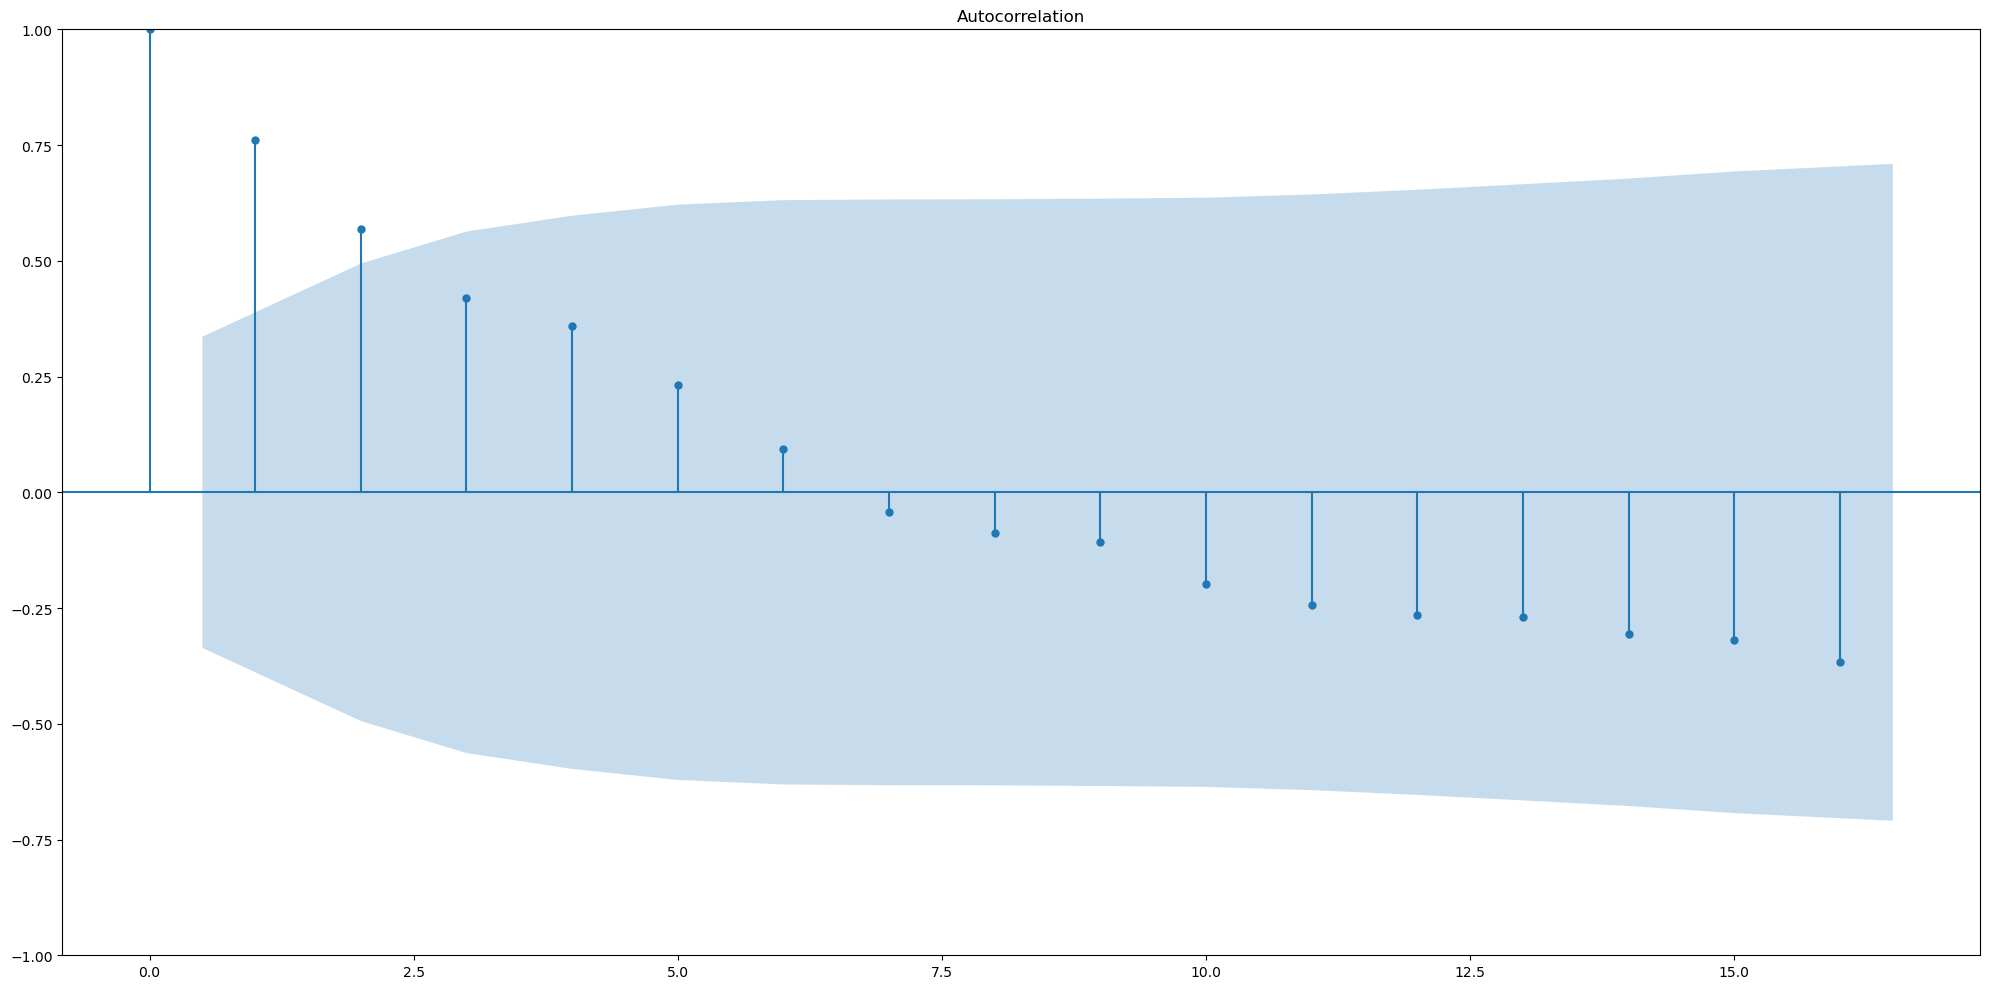

In [225]:
fig = plot_acf(residuals)
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

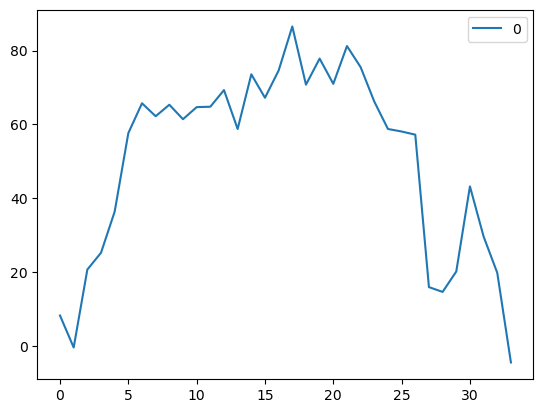

In [226]:
# plot residuals
residuals.plot()
plt.show()

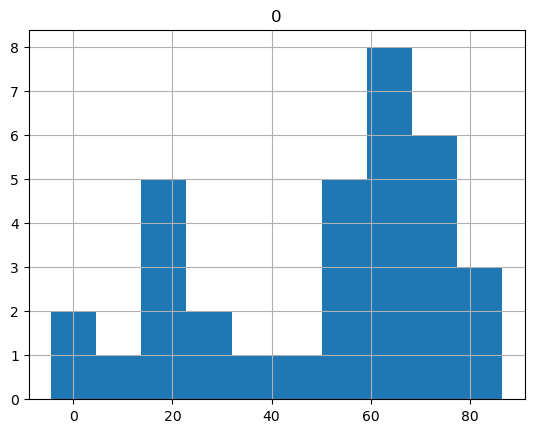

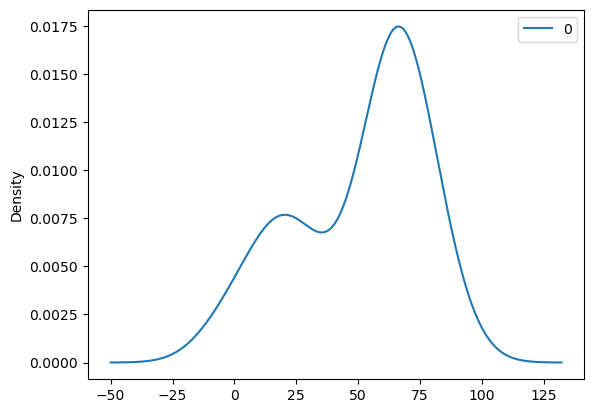

In [227]:
# histogram plot
residuals.hist()
plt.show()
# density plot
residuals.plot(kind='kde')
plt.show()

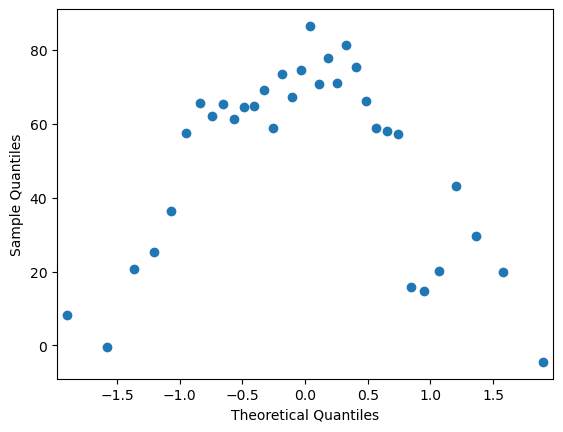

In [228]:
qqplot(residuals)
plt.show()

### Metrics - model evaluation

In [229]:
#define metrics dataframe which will be used below for 
metrics_dataframe = pd.DataFrame(columns=['Model', 'RMSE', 'MAE', 'MAPE'])

                                 
def metrics_cal(actuals, predictions, model):
    mse = mean_squared_error(actuals, predictions)
    rmse = sqrt(mse)
    mae = mean_absolute_error(actuals, predictions)
    mape = np.mean(np.abs((actuals - predictions) / actuals)) * 100
    
    df = pd.DataFrame({'Model': model,
                       'RMSE': rmse,
                       'MAE': mae, 
                       'MAPE': mape}, index=[0])
    dataframe = metrics_dataframe.append(df)
    return dataframe

In [230]:
#get all the metrics

metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                ins_cast1.values.flatten(), 
                                'Simple 0.2')

metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                ins_cast2.values.flatten(), 
                                'Simple 0.5')

metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                ins_cast3.values.flatten(), 
                                'Simple 1')

metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                double_ets_add_pred.values.flatten(), 
                                'Double Add')

metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                double_ets_mul_pred.values.flatten(), 
                                'Double Mul')


metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                triple_ets_add_pred.values.flatten(), 
                                'Triple Add')

metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                triple_ets_mul_pred.values.flatten(), 
                                'Triple Mul')

/var/folders/4t/5kfn01f90x98spyfn6qz87100000gn/T/ipykernel_10430/3815975548.py:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  dataframe = metrics_dataframe.append(df)
/var/folders/4t/5kfn01f90x98spyfn6qz87100000gn/T/ipykernel_10430/3815975548.py:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  dataframe = metrics_dataframe.append(df)
/var/folders/4t/5kfn01f90x98spyfn6qz87100000gn/T/ipykernel_10430/3815975548.py:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  dataframe = metrics_dataframe.append(df)
/var/folders/4t/5kfn01f90x98spyfn6qz87100000gn/T/ipykernel_10430/3815975548.py:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  dataf

In [231]:
metrics_dataframe

,Model,RMSE,MAE,MAPE
0,Simple 0.2,60.733549,55.199398,35.649657
0,Simple 0.5,58.291168,52.647512,33.889609
0,Simple 1,57.398429,51.712912,33.246759
0,Double Add,43.506264,38.768587,25.296427
0,Double Mul,39.410758,35.881510,25.100641
0,Triple Add,42.114899,37.812334,24.852529
0,Triple Mul,34.328017,27.611270,20.784727


In [232]:
close.tail(12).mean()

Close    132.907938
dtype: float64

In [233]:
triple_ets_add_pred.values.flatten()

array([ 95.02480252,  96.31860815,  97.33344119,  98.06308866,
        98.41996497,  99.38659759, 100.22226888, 101.90736207,
       103.45531003, 105.21375884, 106.97746845, 108.73452723,
       109.05536904, 111.39235843, 113.07764826, 114.26808596,
       115.93337682, 118.14139378, 117.92373544, 117.38024314,
       117.27802041, 118.85561666, 120.04327108, 121.96015672,
       123.57461834, 124.64984072, 125.61800615, 127.46422279,
       127.60316526, 127.99582724, 128.39836336, 129.43890572,
       130.14201202, 131.49632636])

In [234]:
# Create a data frame with all the predictions along with the test data
test_pred_df = test_data.copy()

# Add all predictions 
test_pred_df = test_pred_df.assign(SimpleExp_1_pred = ins_cast3.values.flatten(),
                                   Double_add_pred = double_ets_add_pred.values.flatten(),
                                   Triple_add_pred = triple_ets_add_pred.values.flatten())

test_pred_df

,Close,SimpleExp_1_pred,Double_add_pred,Triple_add_pred
Date,,,,
2020-02-01,103.237747,94.0275,95.072098,95.024803
2020-03-01,94.591003,94.0275,96.116697,96.318608
2020-04-01,115.704002,94.0275,97.161295,97.333441
2020-05-01,120.252499,94.0275,98.205894,98.063089
2020-06-01,131.406250,94.0275,99.250492,98.419965
2020-07-01,152.677246,94.0275,100.295091,99.386598
2020-08-01,160.750748,94.0275,101.339689,100.222269
2020-09-01,157.244003,94.0275,102.384287,101.907362
2020-10-01,160.356255,94.0275,103.428886,103.455310


In [235]:
# Create an average prediction from the three and check its metrics
test_pred_df['Average_Predictions'] = (test_pred_df['SimpleExp_1_pred']+test_pred_df['Double_add_pred']+test_pred_df['Triple_add_pred'])/3
test_pred_df

,Close,SimpleExp_1_pred,Double_add_pred,Triple_add_pred,Average_Predictions
Date,,,,,
2020-02-01,103.237747,94.0275,95.072098,95.024803,94.708134
2020-03-01,94.591003,94.0275,96.116697,96.318608,95.487602
2020-04-01,115.704002,94.0275,97.161295,97.333441,96.174079
2020-05-01,120.252499,94.0275,98.205894,98.063089,96.765494
2020-06-01,131.406250,94.0275,99.250492,98.419965,97.232652
2020-07-01,152.677246,94.0275,100.295091,99.386598,97.903063
2020-08-01,160.750748,94.0275,101.339689,100.222269,98.529819
2020-09-01,157.244003,94.0275,102.384287,101.907362,99.439716
2020-10-01,160.356255,94.0275,103.428886,103.455310,100.303899


In [236]:
metrics_dataframe = metrics_cal(test_data.values.flatten(), 
                                test_pred_df['Average_Predictions'].values.flatten(), 
                                'Average')

metrics_dataframe

/var/folders/4t/5kfn01f90x98spyfn6qz87100000gn/T/ipykernel_10430/3815975548.py:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  dataframe = metrics_dataframe.append(df)


,Model,RMSE,MAE,MAPE
0,Simple 0.2,60.733549,55.199398,35.649657
0,Simple 0.5,58.291168,52.647512,33.889609
0,Simple 1,57.398429,51.712912,33.246759
0,Double Add,43.506264,38.768587,25.296427
0,Double Mul,39.410758,35.881510,25.100641
0,Triple Add,42.114899,37.812334,24.852529
0,Triple Mul,34.328017,27.611270,20.784727
0,Average,47.024401,41.144786,26.374398


In [237]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,34.328017,27.611270,20.784727
0,Double Mul,39.410758,35.881510,25.100641
0,Triple Add,42.114899,37.812334,24.852529
0,Double Add,43.506264,38.768587,25.296427
0,Average,47.024401,41.144786,26.374398
0,Simple 1,57.398429,51.712912,33.246759
0,Simple 0.5,58.291168,52.647512,33.889609
0,Simple 0.2,60.733549,55.199398,35.649657


## Conclusion

The Amazon stock market is one of the most interesting stocks. At the beginning, it was lower than eBay; however, by 2016 it surpassed its competitor. Another interesting factor is that, at first glance, the data may seem to have many outliers; however, this is due to the stock's exponential growth. It would be interesting to analyze the stock with further indicators and seasonalities such as political turmoil.